In [1]:
import numpy as np
import pandas as pd
import re

In [2]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('gurgaon_properties_cleaned_v1.csv')

In [4]:
df.duplicated().sum()

np.int64(122)

In [5]:
df.head(1)
# focus is on -> areaWithType, additionalRoom, agePossession, furnishDetails, features 

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features
0,house,international city by sobha phase 2,sector 109,11.25,25000.0,4500.0,Plot area 500(418.06 sq.m.),7,5,3+,"pooja room,study room,servant room",4.0,North-East,1 to 5 Year Old,"['Dwarka Sector 21 Metro Station', 'Pacific D21 Mall', 'Dwarka Expressway', 'Euro International School', 'The NorthCap University', 'Aryan Hospital', 'Indira Gandhi Intl Airport', 'Gurgaon Railway Station']",NaN,"['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Maintenance Staff', 'Park', 'Visitor Parking', 'Rain Water Harvesting']"


## 1. areaWithType

In [6]:
df.sample(5)[['price','area','areaWithType']]

,price,area,areaWithType
1861,10.85,3762.0,Plot area 418(349.5 sq.m.)
1736,6.40,3150.0,Plot area 350(292.64 sq.m.)Built Up area: 349 sq.yards (291.81 sq.m.)Carpet area: 348 sq.yards (290.97 sq.m.)
533,0.95,1307.0,Carpet area: 1307 (121.42 sq.m.)
3298,2.15,2149.0,Super Built up area 2149(199.65 sq.m.)
43,4.25,3880.0,Super Built up area 3880(360.46 sq.m.)


In [7]:
# This function extracts the Super Built up area
def get_super_built_up_area(text):
    match = re.search(r'Super Built up area (\d+\.?\d*)', text)
    if match:
        return float(match.group(1))
    return None

In [8]:
# This function extracts the Built Up area or Carpet area
def get_area(text, area_type):
    match = re.search(area_type + r'\s*:\s*(\d+\.?\d*)', text)
    if match:
        return float(match.group(1))
    return None

In [9]:
# This function checks if the area is provided in sq.m. and converts it to sqft if needed
def convert_to_sqft(text, area_value):
    if area_value is None:
        return None
    match = re.search(r'{} \((\d+\.?\d*) sq.m.\)'.format(area_value), text)
    if match:
        sq_m_value = float(match.group(1))
        return sq_m_value * 10.7639  # conversion factor from sq.m. to sqft
    return area_value

In [10]:
# Extract Super Built up area and convert to sqft if needed
df['super_built_up_area'] = df['areaWithType'].apply(get_super_built_up_area)
df['super_built_up_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['super_built_up_area']), axis=1)

# Extract Built Up area and convert to sqft if needed
df['built_up_area'] = df['areaWithType'].apply(lambda x: get_area(x, 'Built Up area'))
df['built_up_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['built_up_area']), axis=1)

# Extract Carpet area and convert to sqft if needed
df['carpet_area'] = df['areaWithType'].apply(lambda x: get_area(x, 'Carpet area'))
df['carpet_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['carpet_area']), axis=1)

In [11]:
df[['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].sample(5)

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
3625,17.00,house,4842.0,Plot area 4842(449.84 sq.m.)Built Up area: 9000 sq.ft. (836.13 sq.m.),NaN,9000.0,NaN
2332,8.50,house,3240.0,Plot area 360(301.01 sq.m.),NaN,NaN,NaN
465,0.65,house,1000.0,Carpet area: 1000 (92.9 sq.m.),NaN,NaN,1000.0
1633,0.38,house,50.0,Carpet area: 50 (4.65 sq.m.),NaN,NaN,50.0
2745,0.90,flat,683.0,Built Up area: 683 (63.45 sq.m.),NaN,683.0,NaN


In [12]:
df.duplicated().sum()

np.int64(122)

In [13]:
df[~((df['super_built_up_area'].isnull()) | (df['built_up_area'].isnull()) | (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].shape

(534, 7)

In [14]:
df[df['areaWithType'].str.contains('Plot')][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].head(5)

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
0,11.25,house,4500.0,Plot area 500(418.06 sq.m.),NaN,NaN,NaN
10,10.50,house,402.0,Plot area 402(37.35 sq.m.),NaN,NaN,NaN
11,5.70,house,2518.0,Plot area 270(225.75 sq.m.),NaN,NaN,NaN
21,0.38,house,900.0,Plot area 900(83.61 sq.m.),NaN,NaN,NaN
29,4.50,house,2880.0,Plot area 320(267.56 sq.m.),NaN,NaN,NaN


In [15]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                    18
price_per_sqft           18
area                     18
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
additionalRoom         1587
floorNum                 19
facing                 1105
agePossession             1
nearbyLocations         177
furnishDetails          981
features                635
super_built_up_area    1888
built_up_area          2616
carpet_area            1859
dtype: int64

In [16]:
all_nan_df = df[((df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']]

In [17]:
all_nan_df.head()

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
0,11.25,house,4500.0,Plot area 500(418.06 sq.m.),NaN,NaN,NaN
10,10.50,house,402.0,Plot area 402(37.35 sq.m.),NaN,NaN,NaN
11,5.70,house,2518.0,Plot area 270(225.75 sq.m.),NaN,NaN,NaN
21,0.38,house,900.0,Plot area 900(83.61 sq.m.),NaN,NaN,NaN
29,4.50,house,2880.0,Plot area 320(267.56 sq.m.),NaN,NaN,NaN


In [18]:
all_nan_index = df[((df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].index

In [19]:
# Function to extract plot area from 'areaWithType' column
def extract_plot_area(area_with_type):
    match = re.search(r'Plot area (\d+\.?\d*)', area_with_type)
    return float(match.group(1)) if match else None

In [20]:
all_nan_df['built_up_area'] = all_nan_df['areaWithType'].apply(extract_plot_area)

# Update the original dataframe
#gurgaon_properties.update(filtered_rows)

In [21]:
all_nan_df

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
0,11.25,house,4500.0,Plot area 500(418.06 sq.m.),NaN,500.00,NaN
10,10.50,house,402.0,Plot area 402(37.35 sq.m.),NaN,402.00,NaN
11,5.70,house,2518.0,Plot area 270(225.75 sq.m.),NaN,270.00,NaN
21,0.38,house,900.0,Plot area 900(83.61 sq.m.),NaN,900.00,NaN
29,4.50,house,2880.0,Plot area 320(267.56 sq.m.),NaN,320.00,NaN
33,9.50,house,3600.0,Plot area 400(334.45 sq.m.),NaN,400.00,NaN
38,1.25,house,82781.0,Plot area 115(7692.86 sq.m.),NaN,115.00,NaN
49,6.75,house,2115.0,Plot area 235(196.49 sq.m.),NaN,235.00,NaN
55,11.50,house,2736.0,Plot area 304(254.18 sq.m.),NaN,304.00,NaN
56,5.88,house,2160.0,Plot area 240(200.67 sq.m.),NaN,240.00,NaN


In [22]:
def convert_scale(row):
    if np.isnan(row['area']) or np.isnan(row['built_up_area']):
        return row['built_up_area']
    else:
        if round(row['area']/row['built_up_area']) == 9.0:
            return row['built_up_area'] * 9
        elif round(row['area']/row['built_up_area']) == 11.0:
            return row['built_up_area'] * 10.7
        else:
            return row['built_up_area']

In [23]:
all_nan_df['built_up_area'] = all_nan_df.apply(convert_scale,axis=1)

In [24]:
all_nan_df

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
0,11.25,house,4500.0,Plot area 500(418.06 sq.m.),NaN,4500.00,NaN
10,10.50,house,402.0,Plot area 402(37.35 sq.m.),NaN,402.00,NaN
11,5.70,house,2518.0,Plot area 270(225.75 sq.m.),NaN,2430.00,NaN
21,0.38,house,900.0,Plot area 900(83.61 sq.m.),NaN,900.00,NaN
29,4.50,house,2880.0,Plot area 320(267.56 sq.m.),NaN,2880.00,NaN
33,9.50,house,3600.0,Plot area 400(334.45 sq.m.),NaN,3600.00,NaN
38,1.25,house,82781.0,Plot area 115(7692.86 sq.m.),NaN,115.00,NaN
49,6.75,house,2115.0,Plot area 235(196.49 sq.m.),NaN,2115.00,NaN
55,11.50,house,2736.0,Plot area 304(254.18 sq.m.),NaN,2736.00,NaN
56,5.88,house,2160.0,Plot area 240(200.67 sq.m.),NaN,2160.00,NaN


In [25]:
# update the original dataframe
df.update(all_nan_df)

In [26]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                    18
price_per_sqft           18
area                     18
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
additionalRoom         1587
floorNum                 19
facing                 1105
agePossession             1
nearbyLocations         177
furnishDetails          981
features                635
super_built_up_area    1888
built_up_area          2070
carpet_area            1859
dtype: int64

In [27]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area
0,house,international city by sobha phase 2,sector 109,11.25,25000.0,4500.0,Plot area 500(418.06 sq.m.),7,5,3+,"pooja room,study room,servant room",4.0,North-East,1 to 5 Year Old,"['Dwarka Sector 21 Metro Station', 'Pacific D21 Mall', 'Dwarka Expressway', 'Euro International School', 'The NorthCap University', 'Aryan Hospital', 'Indira Gandhi Intl Airport', 'Gurgaon Railway Station']",NaN,"['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Maintenance Staff', 'Park', 'Visitor Parking', 'Rain Water Harvesting']",NaN,4500.0,NaN
1,flat,smart world gems,sector 89,1.00,9007.0,1110.0,Carpet area: 1110 (103.12 sq.m.),2,2,3,"study room,others",3.0,NaN,0 to 1 Year Old,"['Sant Soordas Sihi Metro Station', 'Airia Mall', 'Dwarka Expressway', 'Pataudi Road', 'NH-8', 'KMP Expressway', 'RPS International School', 'Genesis Hospital Sector 84', 'Gurgaon Railway Station', 'Vatika Business Park Sector 49', 'Holiday Inn Gurugram Sector 90', 'De Adventure Amusement Park', 'National Tennis Academy Sector 98', 'IMT Manesar']",[],"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'No open drainage around', 'Piped-gas', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Club house / Community Center']",NaN,NaN,1110.0
2,flat,hcbs sports ville,sohna road,0.32,6165.0,519.0,Carpet area: 519 (48.22 sq.m.),2,2,2,NaN,2.0,NaN,0 to 1 Year Old,"['The roadside cafe', 'GD Goenka Mess', 'ROyal Kitchen', 'Mithaas Wala', 'Momomia Gurgoan']",NaN,"['Intercom Facility', 'Lift(s)', 'Swimming Pool', 'Park', 'Shopping Centre', 'Rain Water Harvesting']",NaN,NaN,519.0
3,flat,shree vardhman flora,sector 90,0.70,5177.0,1352.0,Super Built up area 1352(125.6 sq.m.),2,2,3,study room,9.0,East,0 to 1 Year Old,"['IRIS Broadway Mall', 'Dwarka Expressway', 'Saraswati Model School', 'SGT University', 'Aarvy Healthcare Hospital', 'Indira Gandhi International Airport', 'Garhi Harsaru Junction', 'Orchid Business Park', 'Holiday Inn Gurugram Sector 90', 'Flying Wings Badminton Academy']",NaN,"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Rain Water Harvesting', 'Club house / Community Center']",1352.0,NaN,NaN
4,flat,signature the roselia,sector 95,0.45,7.0,642857.0,Carpet area: 569243 (52884.41 sq.m.),2,2,2,NaN,2.0,South-West,0 to 1 Year Old,"['Newtown Square Mall', 'Pataudi Road', 'Dwarka Expressway', 'NH-48', 'Yaduvanshi Shiksha Niketan', 'Gurugram University Sector 87', 'Aarvy Healthcare', 'Indira Gandhi International Airport', 'IMT Manesar', 'Holiday Inn Sector 90', 'National Tennis Academy', 'CNG Petrol Pump']",NaN,"['Security / Fire Alarm', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'No open drainage around', 'Visitor Parking', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Low Density Society', 'Shopping Centre', 'Waste Disposal', 'Club house / Community Center', 'Water softening plant']",NaN,NaN,569243.0


## 2.additionalRoom

In [28]:
df['additionalRoom'].value_counts()

additionalRoom
servant room                                     705
study room                                       250
others                                           225
pooja room                                       165
store room                                        99
study room,servant room                           99
pooja room,servant room                           82
pooja room,study room,servant room,store room     72
servant room,others                               60
pooja room,study room,servant room                55
pooja room,study room,servant room,others         54
servant room,pooja room                           38
servant room,store room                           33
study room,others                                 29
pooja room,study room                             22
pooja room,others                                 17
pooja room,store room                             15
servant room,study room                           12
pooja room,store room,study roo

In [29]:
# additional room
# List of new columns to be created
new_cols = ['study room', 'servant room', 'store room', 'pooja room', 'others']

# Populate the new columns based on the "additionalRoom" column
for col in new_cols:
    df[col] = df['additionalRoom'].str.contains(col).astype(int)

In [30]:
df.sample(5)[['additionalRoom','study room', 'servant room', 'store room', 'pooja room', 'others']]

,additionalRoom,study room,servant room,store room,pooja room,others
1857,NaN,0,0,0,0,0
10,"pooja room,servant room",0,1,0,1,0
3265,NaN,0,0,0,0,0
371,NaN,0,0,0,0,0
2457,NaN,0,0,0,0,0


In [31]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others
0,house,international city by sobha phase 2,sector 109,11.25,25000.0,4500.0,Plot area 500(418.06 sq.m.),7,5,3+,"pooja room,study room,servant room",4.0,North-East,1 to 5 Year Old,"['Dwarka Sector 21 Metro Station', 'Pacific D21 Mall', 'Dwarka Expressway', 'Euro International School', 'The NorthCap University', 'Aryan Hospital', 'Indira Gandhi Intl Airport', 'Gurgaon Railway Station']",NaN,"['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Maintenance Staff', 'Park', 'Visitor Parking', 'Rain Water Harvesting']",NaN,4500.0,NaN,1,1,0,1,0
1,flat,smart world gems,sector 89,1.00,9007.0,1110.0,Carpet area: 1110 (103.12 sq.m.),2,2,3,"study room,others",3.0,NaN,0 to 1 Year Old,"['Sant Soordas Sihi Metro Station', 'Airia Mall', 'Dwarka Expressway', 'Pataudi Road', 'NH-8', 'KMP Expressway', 'RPS International School', 'Genesis Hospital Sector 84', 'Gurgaon Railway Station', 'Vatika Business Park Sector 49', 'Holiday Inn Gurugram Sector 90', 'De Adventure Amusement Park', 'National Tennis Academy Sector 98', 'IMT Manesar']",[],"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'No open drainage around', 'Piped-gas', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Club house / Community Center']",NaN,NaN,1110.0,1,0,0,0,1
2,flat,hcbs sports ville,sohna road,0.32,6165.0,519.0,Carpet area: 519 (48.22 sq.m.),2,2,2,NaN,2.0,NaN,0 to 1 Year Old,"['The roadside cafe', 'GD Goenka Mess', 'ROyal Kitchen', 'Mithaas Wala', 'Momomia Gurgoan']",NaN,"['Intercom Facility', 'Lift(s)', 'Swimming Pool', 'Park', 'Shopping Centre', 'Rain Water Harvesting']",NaN,NaN,519.0,0,0,0,0,0
3,flat,shree vardhman flora,sector 90,0.70,5177.0,1352.0,Super Built up area 1352(125.6 sq.m.),2,2,3,study room,9.0,East,0 to 1 Year Old,"['IRIS Broadway Mall', 'Dwarka Expressway', 'Saraswati Model School', 'SGT University', 'Aarvy Healthcare Hospital', 'Indira Gandhi International Airport', 'Garhi Harsaru Junction', 'Orchid Business Park', 'Holiday Inn Gurugram Sector 90', 'Flying Wings Badminton Academy']",NaN,"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Rain Water Harvesting', 'Club house / Community Center']",1352.0,NaN,NaN,1,0,0,0,0
4,flat,signature the roselia,sector 95,0.45,7.0,642857.0,Carpet area: 569243 (52884.41 sq.m.),2,2,2,NaN,2.0,South-West,0 to 1 Year Old,"['Newtown Square Mall', 'Pataudi Road', 'Dwarka Expressway', 'NH-48', 'Yaduvanshi Shiksha Niketan', 'Gurugram University Sector 87', 'Aarvy Healthcare', 'Indira Gandhi International Airport', 'IMT Manesar', 'Holiday Inn Sector 90', 'National Tennis Academy', 'CNG Petrol Pump']",NaN,"['Security / Fire Alarm', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'No open drainage around', 'Visitor Parking', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Low Density Society', 'Shopping Centre', 'Waste Disposal', 'Club house / Community Center', 'Water softening plant']",NaN,NaN,569243.0,0,0,0,0,0


## 3.agePossession

In [32]:
df['agePossession'].value_counts()

agePossession
1 to 5 Year Old       1676
5 to 10 Year Old       575
0 to 1 Year Old        530
undefined              332
10+ Year Old           310
Under Construction      90
Within 6 months         70
Within 3 months         26
Dec 2023                22
By 2023                 19
By 2024                 17
Dec 2024                16
Mar 2024                14
Oct 2024                 8
Jan 2024                 8
Jun 2024                 7
Aug 2023                 7
Dec 2025                 7
Nov 2023                 5
Oct 2023                 4
By 2025                  4
Jul 2024                 4
Sep 2023                 4
Aug 2024                 4
May 2024                 3
Nov 2024                 3
Jan 2025                 3
Feb 2024                 3
Jun 2027                 2
Jan 2026                 2
Sep 2025                 2
Mar 2025                 2
Apr 2026                 2
Aug 2025                 2
Dec 2026                 2
Jul 2025                 2
Oct 2025      

In [33]:
def categorize_age_possession(value):
    if pd.isna(value):
        return "Undefined"
    if "0 to 1 Year Old" in value or "Within 6 months" in value or "Within 3 months" in value:
        return "New Property"
    if "1 to 5 Year Old" in value:
        return "Relatively New"
    if "5 to 10 Year Old" in value:
        return "Moderately Old"
    if "10+ Year Old" in value:
        return "Old Property"
    if "Under Construction" in value or "By" in value:
        return "Under Construction"
    try:
        # For entries like 'May 2024'
        int(value.split(" ")[-1])
        return "Under Construction"
    except:
        return "Undefined"

In [34]:
df['agePossession'] = df['agePossession'].apply(categorize_age_possession)

In [35]:
df['agePossession'].value_counts()

agePossession
Relatively New        1676
New Property           626
Moderately Old         575
Undefined              333
Old Property           310
Under Construction     283
Name: count, dtype: int64

In [36]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others
0,house,international city by sobha phase 2,sector 109,11.25,25000.0,4500.0,Plot area 500(418.06 sq.m.),7,5,3+,"pooja room,study room,servant room",4.0,North-East,Relatively New,"['Dwarka Sector 21 Metro Station', 'Pacific D21 Mall', 'Dwarka Expressway', 'Euro International School', 'The NorthCap University', 'Aryan Hospital', 'Indira Gandhi Intl Airport', 'Gurgaon Railway Station']",NaN,"['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Maintenance Staff', 'Park', 'Visitor Parking', 'Rain Water Harvesting']",NaN,4500.0,NaN,1,1,0,1,0
1,flat,smart world gems,sector 89,1.00,9007.0,1110.0,Carpet area: 1110 (103.12 sq.m.),2,2,3,"study room,others",3.0,NaN,New Property,"['Sant Soordas Sihi Metro Station', 'Airia Mall', 'Dwarka Expressway', 'Pataudi Road', 'NH-8', 'KMP Expressway', 'RPS International School', 'Genesis Hospital Sector 84', 'Gurgaon Railway Station', 'Vatika Business Park Sector 49', 'Holiday Inn Gurugram Sector 90', 'De Adventure Amusement Park', 'National Tennis Academy Sector 98', 'IMT Manesar']",[],"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'No open drainage around', 'Piped-gas', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Club house / Community Center']",NaN,NaN,1110.0,1,0,0,0,1
2,flat,hcbs sports ville,sohna road,0.32,6165.0,519.0,Carpet area: 519 (48.22 sq.m.),2,2,2,NaN,2.0,NaN,New Property,"['The roadside cafe', 'GD Goenka Mess', 'ROyal Kitchen', 'Mithaas Wala', 'Momomia Gurgoan']",NaN,"['Intercom Facility', 'Lift(s)', 'Swimming Pool', 'Park', 'Shopping Centre', 'Rain Water Harvesting']",NaN,NaN,519.0,0,0,0,0,0
3,flat,shree vardhman flora,sector 90,0.70,5177.0,1352.0,Super Built up area 1352(125.6 sq.m.),2,2,3,study room,9.0,East,New Property,"['IRIS Broadway Mall', 'Dwarka Expressway', 'Saraswati Model School', 'SGT University', 'Aarvy Healthcare Hospital', 'Indira Gandhi International Airport', 'Garhi Harsaru Junction', 'Orchid Business Park', 'Holiday Inn Gurugram Sector 90', 'Flying Wings Badminton Academy']",NaN,"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Rain Water Harvesting', 'Club house / Community Center']",1352.0,NaN,NaN,1,0,0,0,0
4,flat,signature the roselia,sector 95,0.45,7.0,642857.0,Carpet area: 569243 (52884.41 sq.m.),2,2,2,NaN,2.0,South-West,New Property,"['Newtown Square Mall', 'Pataudi Road', 'Dwarka Expressway', 'NH-48', 'Yaduvanshi Shiksha Niketan', 'Gurugram University Sector 87', 'Aarvy Healthcare', 'Indira Gandhi International Airport', 'IMT Manesar', 'Holiday Inn Sector 90', 'National Tennis Academy', 'CNG Petrol Pump']",NaN,"['Security / Fire Alarm', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'No open drainage around', 'Visitor Parking', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Low Density Society', 'Shopping Centre', 'Waste Disposal', 'Club house / Community Center', 'Water softening plant']",NaN,NaN,569243.0,0,0,0,0,0


## 4.furnishDetails

In [37]:
df.sample(5)[['furnishDetails','features']]

,furnishDetails,features
508,"['1 Fan', '1 Light', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Geyser', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']","['Intercom Facility', 'Lift(s)', 'Park']"
1465,NaN,"['Intercom Facility', 'Lift(s)', 'Swimming Pool', 'Park', 'Shopping Centre', 'Fitness Centre / GYM', 'Club house / Community Center']"
3349,NaN,NaN
1622,NaN,"['Water purifier', 'Security / Fire Alarm', 'Power Back-up', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Intercom Facility', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Piped-gas', 'Internet/wi-fi connectivity', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Spacious Interiors', 'Low Density Society', 'Waste Disposal', 'Rain Water Harvesting', 'Water softening plant', 'Shopping Centre', 'Fitness Centre / GYM', 'Club house / Community Center']"
3206,NaN,"['Lift(s)', 'Feng Shui / Vaastu Compliant', 'Piped-gas', 'Park', 'Swimming Pool', 'Club house / Community Center', 'Fitness Centre / GYM', 'Shopping Centre', 'Rain Water Harvesting']"


In [38]:
# Extract all unique furnishings from the furnishDetails column
all_furnishings = []
for detail in df['furnishDetails'].dropna():
    furnishings = detail.replace('[', '').replace(']', '').replace("'", "").split(', ')
    all_furnishings.extend(furnishings)
unique_furnishings = list(set(all_furnishings))

# Define a function to extract the count of a furnishing from the furnishDetails
def get_furnishing_count(details, furnishing):
    if isinstance(details, str):
        if f"No {furnishing}" in details:
            return 0
        pattern = re.compile(f"(\d+) {furnishing}")
        match = pattern.search(details)
        if match:
            return int(match.group(1))
        elif furnishing in details:
            return 1
    return 0

# Simplify the furnishings list by removing "No" prefix and numbers
columns_to_include = [re.sub(r'No |\d+', '', furnishing).strip() for furnishing in unique_furnishings]
columns_to_include = list(set(columns_to_include))  # Get unique furnishings
columns_to_include = [furnishing for furnishing in columns_to_include if furnishing]  # Remove empty strings

# Create new columns for each unique furnishing and populate with counts
for furnishing in columns_to_include:
    df[furnishing] = df['furnishDetails'].apply(lambda x: get_furnishing_count(x, furnishing))

# Create the new dataframe with the required columns
furnishings_df = df[['furnishDetails'] + columns_to_include]


In [39]:
furnishings_df.shape

(3803, 19)

In [40]:
furnishings_df.drop(columns=['furnishDetails'],inplace=True)

In [41]:
furnishings_df.sample(5)

,Stove,Bed,Fan,Fridge,Curtains,AC,Dining Table,Washing Machine,Water Purifier,Chimney,Modular Kitchen,Light,Microwave,Exhaust Fan,Wardrobe,Sofa,TV,Geyser
656,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3307,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3320,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1082,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1218,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [42]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [43]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(furnishings_df)

In [44]:
wcss_reduced = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(scaled_data)
    wcss_reduced.append(kmeans.inertia_)

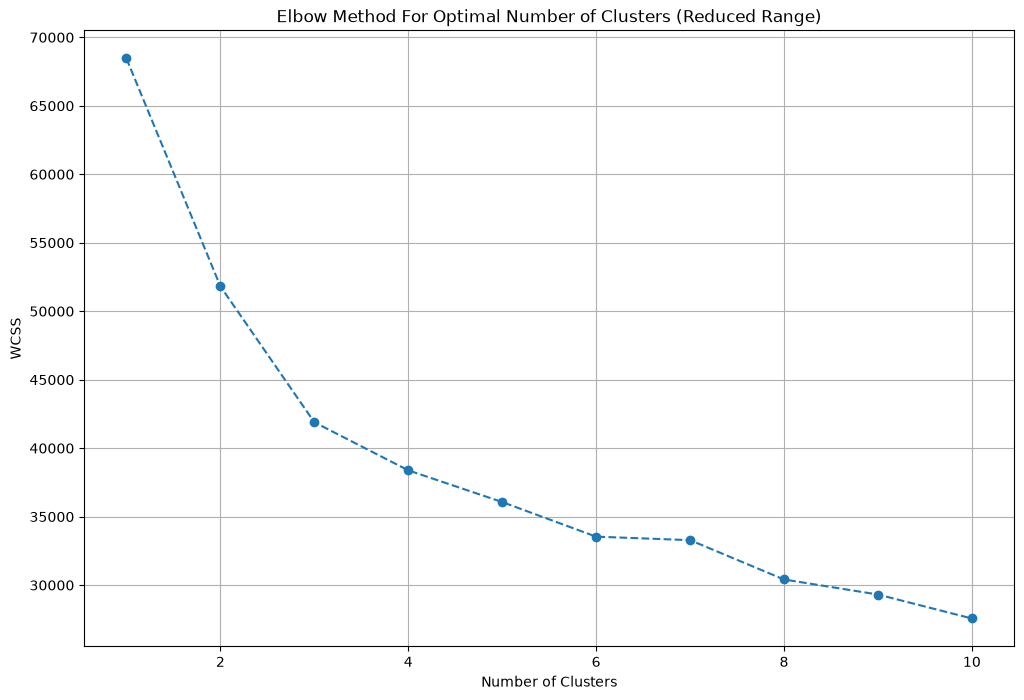

In [45]:
# Plot the results
plt.figure(figsize=(12, 8))
plt.plot(range(1,11), wcss_reduced, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal Number of Clusters (Reduced Range)')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [46]:
n_clusters = 3

# Fit the KMeans model
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans.fit(scaled_data)

# Predict the cluster assignments for each row
cluster_assignments = kmeans.predict(scaled_data)

In [47]:
df = df.iloc[:,:-18]

In [48]:
df['furnishing_type'] = cluster_assignments

In [49]:
df.sample(5)[['furnishDetails','furnishing_type']]
# 0 -> unfurnished
# 1 -> semifurnished
# 2 -> furnished

,furnishDetails,furnishing_type
2164,NaN,0
3121,NaN,0
3074,"['1 Stove', '6 AC', '1 Chimney', '1 Modular Kitchen', '1 Wardrobe', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Geyser', 'No Light', 'No Microwave', 'No Fridge', 'No Sofa', 'No TV', 'No Washing Machine', 'No Water Purifier']",2
2549,"['3 Wardrobe', '4 Fan', '1 Exhaust Fan', '4 Geyser', '1 Stove', '8 Light', '1 Chimney', '1 Modular Kitchen', '4 AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No TV', 'No Washing Machine', 'No Water Purifier']",2
785,"['4 Wardrobe', '6 AC', '1 Modular Kitchen', '1 Chimney', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Geyser', 'No Light', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']",0


## 5.features

In [50]:
df[['society','features']].sample(5)

,society,features
3182,ss residency,"['Intercom Facility', 'Lift(s)', 'Water Storage']"
670,tulip violet,"['Power Back-up', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Piped-gas', 'Visitor Parking', 'Swimming Pool', 'Park', 'Natural Light', 'Airy Rooms', 'Low Density Society', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center']"
620,tulip yellow,NaN
1875,apartment,"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Recently Renovated', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center']"
1748,sare crescent parc,NaN


In [51]:
df['features'].isnull().sum()

np.int64(635)

In [52]:
import pandas as pd
app_df = pd.read_csv('appartments.csv')
app_df.head(2)

FileNotFoundError: [Errno 2] No such file or directory: 'appartments.csv'

In [ ]:
app_df['PropertyName'] = app_df['PropertyName'].str.lower()

In [ ]:
temp_df = df[df['features'].isnull()]

In [ ]:
temp_df.shape

In [ ]:
x = temp_df.merge(app_df,left_on='society',right_on='PropertyName',how='left')['TopFacilities']

In [ ]:
df.loc[temp_df.index,'features'] = x.values

In [ ]:
df['features'].isnull().sum()

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer
import ast

In [ ]:
# Convert the string representation of lists in the 'features' column to actual lists
df['features_list'] = df['features'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) and x.startswith('[') else [])

# Use MultiLabelBinarizer to convert the features list into a binary matrix
mlb = MultiLabelBinarizer()
features_binary_matrix = mlb.fit_transform(df['features_list'])

# Convert the binary matrix into a DataFrame
features_binary_df = pd.DataFrame(features_binary_matrix, columns=mlb.classes_)

In [ ]:
features_binary_df.sample(5)

In [ ]:
features_binary_df.shape

In [ ]:
wcss_reduced = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(features_binary_df)
    wcss_reduced.append(kmeans.inertia_)

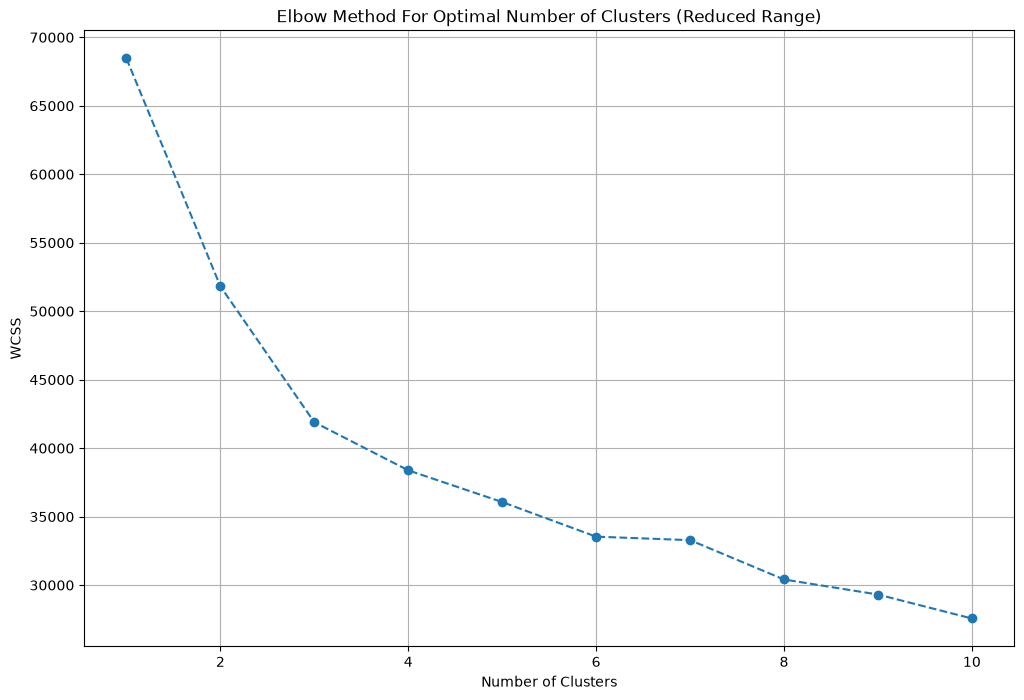

In [53]:
# Plot the results
plt.figure(figsize=(12, 8))
plt.plot(range(1,11), wcss_reduced, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal Number of Clusters (Reduced Range)')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [54]:
# Define the weights for each feature as provided
# Assigning weights based on perceived luxury contribution
weights = {
    '24/7 Power Backup': 8,
    '24/7 Water Supply': 4,
    '24x7 Security': 7,
    'ATM': 4,
    'Aerobics Centre': 6,
    'Airy Rooms': 8,
    'Amphitheatre': 7,
    'Badminton Court': 7,
    'Banquet Hall': 8,
    'Bar/Chill-Out Lounge': 9,
    'Barbecue': 7,
    'Basketball Court': 7,
    'Billiards': 7,
    'Bowling Alley': 8,
    'Business Lounge': 9,
    'CCTV Camera Security': 8,
    'Cafeteria': 6,
    'Car Parking': 6,
    'Card Room': 6,
    'Centrally Air Conditioned': 9,
    'Changing Area': 6,
    "Children's Play Area": 7,
    'Cigar Lounge': 9,
    'Clinic': 5,
    'Club House': 9,
    'Concierge Service': 9,
    'Conference room': 8,
    'Creche/Day care': 7,
    'Cricket Pitch': 7,
    'Doctor on Call': 6,
    'Earthquake Resistant': 5,
    'Entrance Lobby': 7,
    'False Ceiling Lighting': 6,
    'Feng Shui / Vaastu Compliant': 5,
    'Fire Fighting Systems': 8,
    'Fitness Centre / GYM': 8,
    'Flower Garden': 7,
    'Food Court': 6,
    'Foosball': 5,
    'Football': 7,
    'Fountain': 7,
    'Gated Community': 7,
    'Golf Course': 10,
    'Grocery Shop': 6,
    'Gymnasium': 8,
    'High Ceiling Height': 8,
    'High Speed Elevators': 8,
    'Infinity Pool': 9,
    'Intercom Facility': 7,
    'Internal Street Lights': 6,
    'Internet/wi-fi connectivity': 7,
    'Jacuzzi': 9,
    'Jogging Track': 7,
    'Landscape Garden': 8,
    'Laundry': 6,
    'Lawn Tennis Court': 8,
    'Library': 8,
    'Lounge': 8,
    'Low Density Society': 7,
    'Maintenance Staff': 6,
    'Manicured Garden': 7,
    'Medical Centre': 5,
    'Milk Booth': 4,
    'Mini Theatre': 9,
    'Multipurpose Court': 7,
    'Multipurpose Hall': 7,
    'Natural Light': 8,
    'Natural Pond': 7,
    'Park': 8,
    'Party Lawn': 8,
    'Piped Gas': 7,
    'Pool Table': 7,
    'Power Back up Lift': 8,
    'Private Garden / Terrace': 9,
    'Property Staff': 7,
    'RO System': 7,
    'Rain Water Harvesting': 7,
    'Reading Lounge': 8,
    'Restaurant': 8,
    'Salon': 8,
    'Sauna': 9,
    'Security / Fire Alarm': 9,
    'Security Personnel': 9,
    'Separate entry for servant room': 8,
    'Sewage Treatment Plant': 6,
    'Shopping Centre': 7,
    'Skating Rink': 7,
    'Solar Lighting': 6,
    'Solar Water Heating': 7,
    'Spa': 9,
    'Spacious Interiors': 9,
    'Squash Court': 8,
    'Steam Room': 9,
    'Sun Deck': 8,
    'Swimming Pool': 8,
    'Temple': 5,
    'Theatre': 9,
    'Toddler Pool': 7,
    'Valet Parking': 9,
    'Video Door Security': 9,
    'Visitor Parking': 7,
    'Water Softener Plant': 7,
    'Water Storage': 7,
    'Water purifier': 7,
    'Yoga/Meditation Area': 7
}
# Calculate luxury score for each row
luxury_score = features_binary_df[list(weights.keys())].multiply(list(weights.values())).sum(axis=1)


NameError: name 'features_binary_df' is not defined

In [55]:
df['luxury_score'] = luxury_score

NameError: name 'luxury_score' is not defined

In [56]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type
0,house,international city by sobha phase 2,sector 109,11.25,25000.0,4500.0,Plot area 500(418.06 sq.m.),7,5,3+,"pooja room,study room,servant room",4.0,North-East,Relatively New,"['Dwarka Sector 21 Metro Station', 'Pacific D21 Mall', 'Dwarka Expressway', 'Euro International School', 'The NorthCap University', 'Aryan Hospital', 'Indira Gandhi Intl Airport', 'Gurgaon Railway Station']",NaN,"['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Maintenance Staff', 'Park', 'Visitor Parking', 'Rain Water Harvesting']",NaN,4500.0,NaN,1,1,0,1,0,0
1,flat,smart world gems,sector 89,1.00,9007.0,1110.0,Carpet area: 1110 (103.12 sq.m.),2,2,3,"study room,others",3.0,NaN,New Property,"['Sant Soordas Sihi Metro Station', 'Airia Mall', 'Dwarka Expressway', 'Pataudi Road', 'NH-8', 'KMP Expressway', 'RPS International School', 'Genesis Hospital Sector 84', 'Gurgaon Railway Station', 'Vatika Business Park Sector 49', 'Holiday Inn Gurugram Sector 90', 'De Adventure Amusement Park', 'National Tennis Academy Sector 98', 'IMT Manesar']",[],"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'No open drainage around', 'Piped-gas', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Club house / Community Center']",NaN,NaN,1110.0,1,0,0,0,1,0
2,flat,hcbs sports ville,sohna road,0.32,6165.0,519.0,Carpet area: 519 (48.22 sq.m.),2,2,2,NaN,2.0,NaN,New Property,"['The roadside cafe', 'GD Goenka Mess', 'ROyal Kitchen', 'Mithaas Wala', 'Momomia Gurgoan']",NaN,"['Intercom Facility', 'Lift(s)', 'Swimming Pool', 'Park', 'Shopping Centre', 'Rain Water Harvesting']",NaN,NaN,519.0,0,0,0,0,0,0
3,flat,shree vardhman flora,sector 90,0.70,5177.0,1352.0,Super Built up area 1352(125.6 sq.m.),2,2,3,study room,9.0,East,New Property,"['IRIS Broadway Mall', 'Dwarka Expressway', 'Saraswati Model School', 'SGT University', 'Aarvy Healthcare Hospital', 'Indira Gandhi International Airport', 'Garhi Harsaru Junction', 'Orchid Business Park', 'Holiday Inn Gurugram Sector 90', 'Flying Wings Badminton Academy']",NaN,"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Rain Water Harvesting', 'Club house / Community Center']",1352.0,NaN,NaN,1,0,0,0,0,0
4,flat,signature the roselia,sector 95,0.45,7.0,642857.0,Carpet area: 569243 (52884.41 sq.m.),2,2,2,NaN,2.0,South-West,New Property,"['Newtown Square Mall', 'Pataudi Road', 'Dwarka Expressway', 'NH-48', 'Yaduvanshi Shiksha Niketan', 'Gurugram University Sector 87', 'Aarvy Healthcare', 'Indira Gandhi International Airport', 'IMT Manesar', 'Holiday Inn Sector 90', 'National Tennis Academy', 'CNG Petrol Pump']",NaN,"['Security / Fire Alarm', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'No open drainage around', 'Visitor Parking', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Low Density Society', 'Shopping Centre', 'Waste Disposal', 'Club house / Community Center', 'Water softening plant']",NaN,NaN,569243.0,0,0,0,0,0,0


In [57]:
# cols to drop -> nearbyLocations,furnishDetails, features,features_list, additionalRoom
df.drop(columns=['nearbyLocations','furnishDetails','features','features_list','additionalRoom'],inplace=True)

KeyError: "['features_list'] not found in axis"

In [58]:
df.sample(5)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type
466,flat,shreeram apartment ii,sector 4,0.21,4666.0,450.0,Carpet area: 450 (41.81 sq.m.),1,1,1,NaN,2.0,NaN,Relatively New,"['Chintapurni Mandir', 'State bank ATM', 'Shree Krishna Hospital Gurgaon', 'Dr. Hitesh Dawar', 'Prateek Nursing Home And Polyclinic', 'Kr Dental Hub', 'Esic Hospital Gurugram', 'Bhardwaj Hospital', 'Sneh Hospital Gurgaon', 'Dr. Ashok Jain', 'Jain Sant Phool Chand Ji Charitable Hospital', 'Sarvodya Hospital', 'R K Hospital Gurgaon', 'Pearl Dental Clinic', 'Taneja Hospital', 'Gurgaon Eye Centre', 'Dr. Sindhu Clinic', 'Jiya Clinic', 'Dr. Mittal Clinic', 'Chirag Hospital Pvt. Ltd', 'Yashroop Medical Centre', ""Dr. Anurag's Child Care Clinic"", 'Aryan Hospital', 'Shri Multispeciality Hospital', 'Geeta Nursing Home Gurgaon', 'D.R. Rajnis Gupta Clinic', 'Dr. Madan Clinic', 'Chiranjiv Hospital', 'Ravi Clinic and Health Care Centre', 'Sparsh Hospital Gurgaon', 'Dev Man Kathuria Clinic', 'Swastik Maternity and Medical Centre', 'Bhatnagar Maternity and Nursing Home', 'Satyam Hospital Gurgaon', 'Ankur Clinic and Maternity Home', 'Bindal Clinic', 'Shiv Mahima Patient Care Bureau', 'Dr. Agya Ram Sharma Clinic', 'M.S Hospital', 'Indian bank', 'Kotak bank', 'Hdfc bank', 'State bank of india', 'Pizza Hut', 'St. Michaels Sr. Sec. School', 'Gurgaon railway station', 'Gurgaon railway station', 'Gurgaon railway station', 'Basai dhankot railway station']","['2 Wardrobe', '1 Geyser', '4 Light', '1 AC', '1 Chimney', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Lift(s)', 'Water Storage']",NaN,NaN,450.0,0,0,0,0,0,0
852,flat,sunischit apartments,sector 54,1.75,7954.0,2200.0,Super Built up area 2200(204.39 sq.m.)Built Up area: 1900 sq.ft. (176.52 sq.m.)Carpet area: 1700 sq.ft. (157.94 sq.m.),3,4,3+,servant room,5.0,East,Moderately Old,"['Sector 54 chowk metro station', 'Sector metro station', 'Sector metro station', 'Sector 53-54 metro station', 'Sanatan Dharm Mandir', 'Radhakrishna Shani Mandir', 'Icici bank ATM', 'Citi bank ATM', 'Indusind bank ATM', 'State bank ATM', 'Icici bank ATM', 'Arunodaya Deseret Eye Hospital', 'Surgicare Hospital Gurgaon', 'Kriti Hospital', 'Anand Hospital Gurgaon', 'pracksht hospital', 'Paras Hospital Gurgaon', 'HUDA Office Complex', 'Apollo Pharmacy', 'Medisca', 'Intellion Park', 'HCG CNG Station', 'Heera Fuel Station', 'State bank of india', 'Indusind bank', 'Kotak mahindra bank', 'Hdfc bank', 'Icici bank', 'Axis bank', 'Hdfc bank & atm', 'Hdfc bank and atm', '222', 'Bikanerwala', 'Wat-a-Burger', 'Burger Singh', 'Naivedyam Restaurant', 'Clock tower', 'Pizza Hut', 'Starbucks', ""Carl's Jr."", 'Cafe Tonini', 'Shophouse by Kylin', 'Sagar Ratna', 'Iilm University', 'Sushant College of Arts & Architecture', 'IILM', 'Ansal Institute of Technology', 'Suncity School']","['3 Wardrobe', '5 Fan', '1 Exhaust Fan', '3 Geyser', '11 Light', '1 Chimney', '1 Modular Kitchen', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Separate entry for servant room', 'Piped-gas', 'Visitor Parking', 'Park', 'Security Personnel', 'Natural Light']",2200.0,1900.0,1700.0,0,1,0,0,0,2
1691,flat,la vida by tata housing,sector 113,2.78,10334.0,2690.0,Super Built up area 2690(249.91 sq.m.)Built Up area: 2350 sq.ft. (218.32 sq.m.)Carpet area: 2170 sq.ft. (201.6 sq.m.),3,4,3+,servant room,5.0,North-East,Relatively New,"['Dwarka Sector 21

In [59]:
df.shape

(3803, 26)

In [60]:
df.to_csv('gurgaon_properties_cleaned_v2.csv',index=False)